In [ ]:
from sklearn.datasets import make_classification
import numpy as np

In [ ]:
X,y=make_classification(n_samples=100,n_features=2,n_informative=1,n_redundant=0,
                        n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,
                        class_sep=40)

In [ ]:
import matplotlib.pyplot as plt

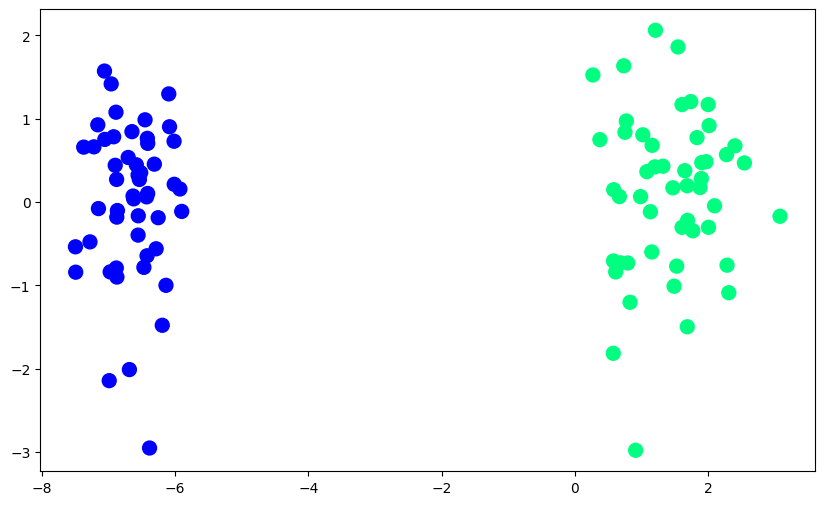

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.show()

## Perceptron Trick

In [ ]:
def step(z):
  return 1 if z>0 else 0
def perceptron(X,y):
  X=np.insert(X,0,1,axis=1)
  weights=np.ones(X.shape[1])
  lr=0.1

  for i in range(1000):
    j=np.random.randint(0,100)
    y_hat=step(np.dot(X[j],weights))
    weights=weights+lr*(y[j]-y_hat)*X[j]
  return weights[0],weights[1:]


In [ ]:
intercept_,coef_=perceptron(X,y)

In [ ]:
print(intercept_)
print(coef_)
#i.e. the line 1.31x+0.157b+1=0

1.1
[1.09140105 0.70190757]


In [ ]:
m=-(coef_[0]/coef_[1])
b=intercept_/coef_[1]

In [ ]:
x_input=np.linspace(-3,3,100)
y_input=m*x_input-b

(-3.0, 2.0)

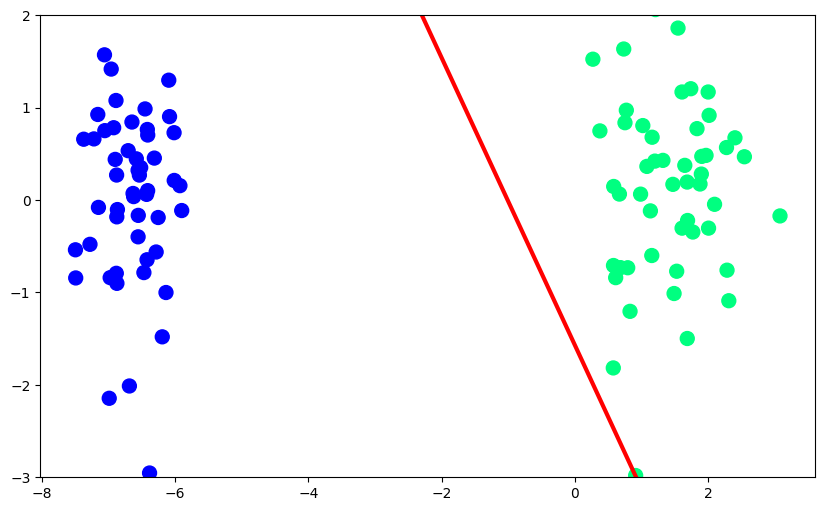

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [ ]:
#Perceptron trick is a simple way to implement logistic regression
#Actually a different function is used

## Logistic Regression using Sklearn

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lor=LogisticRegression()
lor.fit(X,y)

LogisticRegression()

In [ ]:
m = -(lor.coef_[0][0]/lor.coef_[0][1])
b = -(lor.intercept_/lor.coef_[0][1])

In [ ]:
x_input1 = np.linspace(-3,3,100)
y_input1 = m*x_input + b

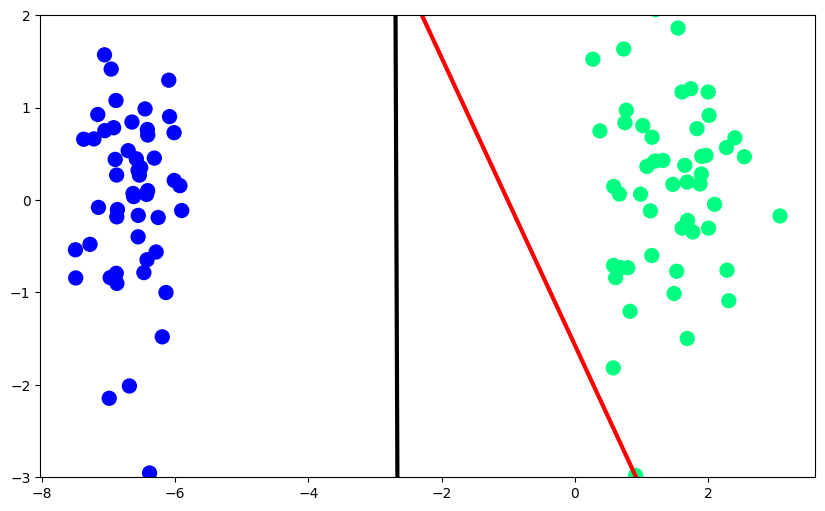

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)
plt.show()

## Using Sigmoid Function

In [ ]:
def sigmoid(z):
  return 1/(1+np.exp(-z))
def Approach2(X,y):
  X=np.insert(X,0,1,axis=1)
  weights=np.ones(X.shape[1])
  lr=0.1

  for i in range(1000):
    j=np.random.randint(0,100)
    y_hat=sigmoid(np.dot(X[j],weights))
    weights=weights+lr*(y[j]-y_hat)*X[j]
  return weights[0],weights[1:]


In [ ]:
def sigmoid(z):
  return 1/(1+np.exp(-z))

In [ ]:
intercept_,coef_=Approach2(X,y)

In [ ]:
m=-(coef_[0]/coef_[1])
b=intercept_/coef_[1]

In [ ]:
x_input2=np.linspace(-3,3,100)
y_input2=m*x_input2+b

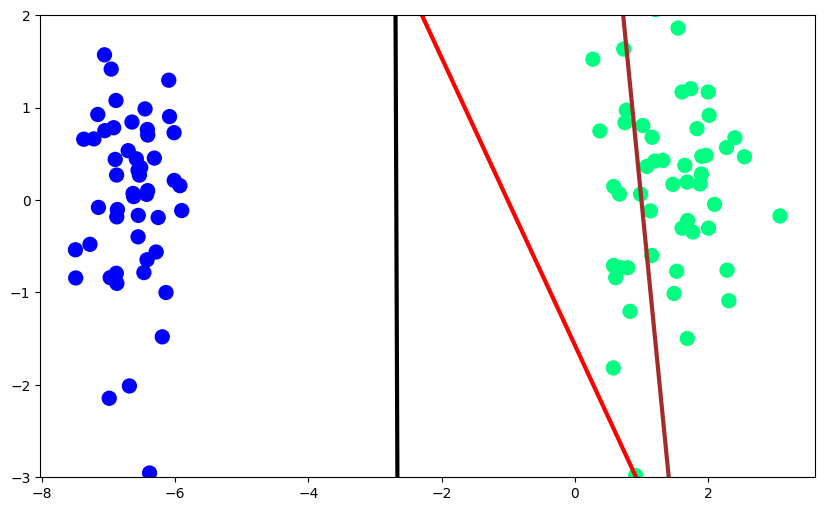

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.plot(x_input2,y_input2,color='brown',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)
plt.show()

## Now The actual LOG_LOSS method

In [ ]:
from sklearn.datasets import make_classification
import numpy as np
X,y=make_classification(n_samples=100,n_features=2,n_informative=1,n_redundant=0,
                        n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,
                        class_sep=20)

In [ ]:
import matplotlib.pyplot as plt

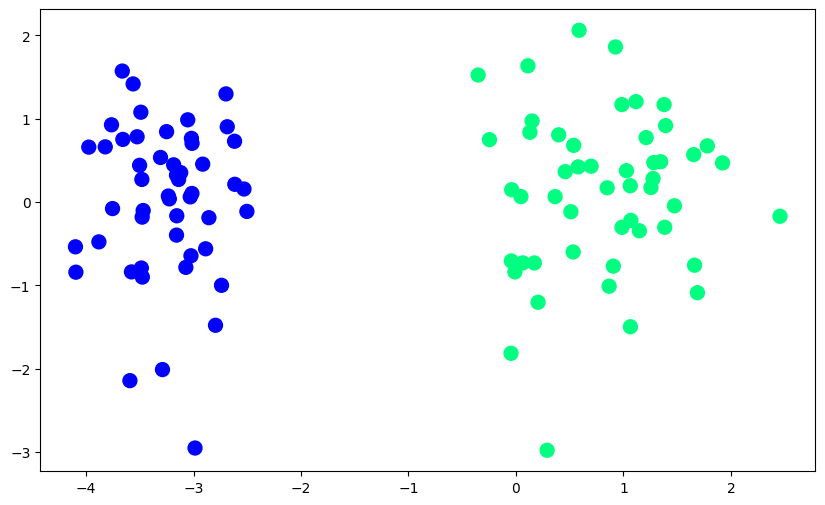

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [ ]:
from sklearn.linear_model import LogisticRegression
lor=LogisticRegression(penalty=None,solver='sag')
lor.fit(X,y)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(penalty=None, solver='sag')

In [ ]:
print(lor.coef_)
print(lor.intercept_)

[[4.85332054 0.22560148]]
[5.82493227]


In [ ]:
m1=-(lor.coef_[0][0])/lor.coef_[0][1]
b1=-(lor.intercept_)/lor.coef_[0][1]

In [ ]:
x_input=np.linspace(-3,3,100)
y_input=m1*x_input+b1

In [ ]:
def gd(X,y):
  X=np.insert(X,0,1,axis=1)
  weights=np.ones(X.shape[1])
  lr=0.5

  for i in range(2500):
    y_hat=sigmoid(np.dot(X,weights))
    weights=weights+lr*(np.dot(y-y_hat,X))/X.shape[0]
  return weights[1:],weights[0]

In [ ]:
def sigmoid(z):
  return 1/(1+np.exp(-z))

In [ ]:
coef_,intercept_=gd(X,y)

In [ ]:
m=-(coef_[0]/coef_[1])
b=-(intercept_/coef_[1])

In [ ]:
x_input1=np.linspace(-3,3,100)
y_input1=m*x_input1+b

(-3.0, 2.0)

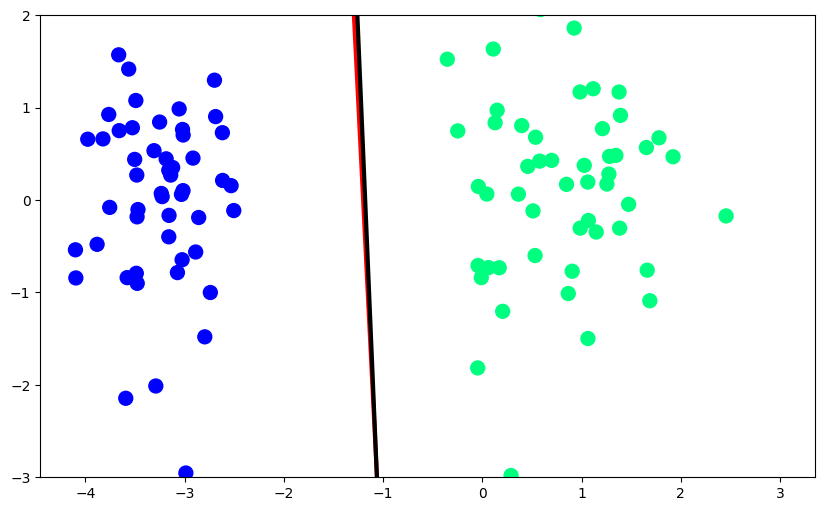

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)